# AAM-DSH Image Retrieval on NUS-WIDE — Colab Notebook

**Adaptive Attention Module — Deep Supervised Hashing for Multi-Label Image Retrieval**

This notebook implements a complete image retrieval pipeline using:
- ResNet-50 backbone with multi-level feature extraction
- Adaptive Attention Modules (AAM) for salient region focus
- Multi-level feature fusion with learnable weights
- Deep supervised hashing with semantic, quantization, and balance losses
- Evaluation on NUS-WIDE dataset with 21 concept labels

**Expected Environment:** Google Colab with GPU (T4/V100/A100)

**Dataset Path:** `/content/drive/MyDrive/NUS_WIDE/`

**Pipeline Steps:**
1. Dataset verification and loading
2. Model architecture construction (ResNet50 + AAM + Fusion + Hash Head)
3. Training with multi-objective loss
4. Binary code generation for database
5. Hamming distance-based retrieval
6. Evaluation with mAP, Precision@K metrics

## Required Package Versions

This notebook uses standard PyTorch deep learning stack:
- `torch >= 1.10.0`
- `torchvision >= 0.11.0`
- `numpy >= 1.21.0`
- `pandas >= 1.3.0`
- `matplotlib >= 3.4.0`
- `scikit-learn >= 0.24.0`
- `Pillow >= 8.0.0`
- `faiss-cpu >= 1.7.0` (optional, for fast binary search)

In [1]:
import sys
import subprocess

# Check and install faiss conditionally
try:
    import faiss
    print("✓ faiss already installed")
except ImportError:
    print("Installing faiss-cpu...")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "faiss-cpu"])
    print("✓ faiss-cpu installed")

Installing faiss-cpu...
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.8/23.8 MB 76.8 MB/s eta 0:00:00
✓ faiss-cpu installed


In [2]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from typing import List, Tuple, Dict, Optional
import json
from pathlib import Path

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision.models as models
import torchvision.transforms as transforms

from sklearn.metrics import average_precision_score

# Try importing faiss
try:
    import faiss
    FAISS_AVAILABLE = True
except ImportError:
    FAISS_AVAILABLE = False
    print("Warning: faiss not available, will use NumPy fallback for Hamming distance")

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
def set_seed(seed=42):
    """Set random seeds for reproducibility."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

set_seed(42)

In [4]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device: {device}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")
    print(f"Memory: {torch.cuda.get_device_properties(0).total_memory / 1e9:.2f} GB")
else:
    print("WARNING: Running on CPU. Training will be very slow!")

Device: cuda
GPU: Tesla T4
Memory: 15.83 GB


## Dataset Configuration

**Root Directory:** `/content/drive/MyDrive/NUS_WIDE/`

**Expected Structure:**
```
/content/drive/MyDrive/NUS_WIDE/
├── images/                      # All image files
├── train_list.txt              # Training image filenames (one per line)
├── test_list.txt               # Test/query image filenames
├── database_list.txt           # Database image filenames
├── train_label_onehot.txt      # Training labels (N×21 binary matrix)
├── test_label_onehot.txt       # Test labels
├── database_label_onehot.txt   # Database labels
├── img_tc10.txt                # Quick experiment subset (top-10 concepts)
├── targets_tc10.txt            # Labels for tc10 subset
└── targets_onehot_tc10.txt     # One-hot labels for tc10
```

**NUS-WIDE Dataset:** 269,648 images with 21 concept labels (multi-label).
Standard splits use ~10k training, ~2k test, remaining as database.

**To change dataset path:** Modify `DATASET_ROOT` in the next cell only.


In [5]:
# === DATASET CONFIGURATION (KAGGLE VERSION) ===

DATASET_ROOT = "/kaggle/input/nuswide/NUS-WIDE/"
IMAGE_DIR = os.path.join(DATASET_ROOT, "images")

# Your Kaggle dataset only has these files:
TRAIN_LIST = os.path.join(DATASET_ROOT, "database_img.txt")   # use as train
TEST_LIST = os.path.join(DATASET_ROOT, "test_img.txt")
DATABASE_LIST = os.path.join(DATASET_ROOT, "database_img.txt") # same as train

TRAIN_LABELS = os.path.join(DATASET_ROOT, "database_label_onehot.txt")
TEST_LABELS = os.path.join(DATASET_ROOT, "test_label_onehot.txt")
DATABASE_LABELS = os.path.join(DATASET_ROOT, "database_label_onehot.txt")

# Quick experiment files
TC10_LIST = os.path.join(DATASET_ROOT, "img_tc10.txt")
TC10_LABELS = os.path.join(DATASET_ROOT, "targets_onehot_tc10.txt")

# Output paths
OUTPUT_ROOT = "/kaggle/working/"
CHECKPOINT_DIR = os.path.join(OUTPUT_ROOT, "checkpoints")
RESULTS_DIR = os.path.join(OUTPUT_ROOT, "results")
RETRIEVAL_EXAMPLES_DIR = os.path.join(RESULTS_DIR, "retrieval_examples")

os.makedirs(CHECKPOINT_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(RETRIEVAL_EXAMPLES_DIR, exist_ok=True)

NUM_CLASSES = 21
HASH_LENGTH = 64
LATENT_DIM = 512

BATCH_SIZE = 128
NUM_EPOCHS = 15   # reduce for Kaggle GPU
LEARNING_RATE_BACKBONE = 1e-4
LEARNING_RATE_HEAD = 1e-3
WEIGHT_DECAY = 1e-4

LAMBDA_Q = 0.1
LAMBDA_B = 0.01

USE_QUICK_EXPERIMENT = False
USE_PAIRWISE_LOSS = False
SAVE_CHECKPOINT_EVERY = 5

print("Kaggle configuration loaded successfully!")


Kaggle configuration loaded successfully!


In [6]:
def verify_dataset():
    print("="*60)
    print("DATASET VERIFICATION")
    print("="*60)

    # Root check
    if not os.path.exists(DATASET_ROOT):
        raise FileNotFoundError(f"Dataset root not found: {DATASET_ROOT}")
    print("✓ Dataset root exists")

    if not os.path.exists(IMAGE_DIR):
        raise FileNotFoundError(f"Image directory missing: {IMAGE_DIR}")
    print("✓ Image directory exists")

    # Required list files
    required = [TRAIN_LIST, TEST_LIST, DATABASE_LIST, TEST_LABELS, DATABASE_LABELS]
    for p in required:
        if not os.path.exists(p):
            raise FileNotFoundError(f"Missing file: {p}")
    print("✓ All required files exist")

    print("\nLOADING LIST FILES...")
    train_imgs = [l.strip() for l in open(TRAIN_LIST)]
    test_imgs  = [l.strip() for l in open(TEST_LIST)]
    db_imgs    = [l.strip() for l in open(DATABASE_LIST)]

    print(f"Train count (images only): {len(train_imgs)}")
    print(f"Test count: {len(test_imgs)}")
    print(f"Database count: {len(db_imgs)}")

    print("\nLOADING LABEL FILES...")
    test_labels = np.loadtxt(TEST_LABELS)
    db_labels   = np.loadtxt(DATABASE_LABELS)

    print(f"Test labels shape: {test_labels.shape}")
    print(f"Database labels shape: {db_labels.shape}")

    # Map training labels
    # train indices correspond to the first N entries of db_labels
    if len(train_imgs) > len(db_labels):
        raise ValueError("Train list larger than database_label_onehot.txt")

    train_labels = db_labels[:len(train_imgs)]
    print(f"Train labels (mapped from database): {train_labels.shape}")

    print("\n✓ Dataset verification successful")
    return train_imgs, test_imgs, db_imgs, train_labels, test_labels, db_labels

train_imgs, test_imgs, db_imgs, train_labels, test_labels, db_labels = verify_dataset()


DATASET VERIFICATION
✓ Dataset root exists
✓ Image directory exists
✓ All required files exist

LOADING LIST FILES...
Train count (images only): 193734
Test count: 2100
Database count: 193734

LOADING LABEL FILES...
Test labels shape: (2100, 21)
Database labels shape: (193734, 21)
Train labels (mapped from database): (193734, 21)

✓ Dataset verification successful


## Multi-Label Format Explanation

**NUS-WIDE Concept Labels:**

The NUS-WIDE dataset contains 21 concept labels:
`airport, animal, beach, bear, birds, boats, book, bridge, buildings, cars, castle,
cat, computer, coral, cow, dancing, dog, elephant, fish, flags, flower`

**Label Format:**
- Each image can have **multiple labels** (multi-label classification)
- Labels are stored as **one-hot encoded vectors** of shape `(N, 21)`
- Each row is a binary vector where `1` indicates presence of that concept
- Example: `[1, 0, 0, 1, 0, ..., 0]` means image contains "airport" and "bear"

**Relevance Definition for Retrieval:**
Two images are considered **relevant** if they share **at least one common label**.

**Data Type:**
- Labels are stored as float32 arrays with values in {0.0, 1.0}
- Loaded using `np.loadtxt()` which handles numeric text files

## Data Preprocessing Pipeline

**Training Augmentation:**
1. Resize to 256×256
2. Random crop to 224×224
3. Random horizontal flip (p=0.5)
4. Color jitter (brightness, contrast, saturation, hue)
5. Normalize with ImageNet statistics

**Validation/Test/Database (No Augmentation):**
1. Resize to 256×256
2. Center crop to 224×224
3. Normalize with ImageNet statistics

**ImageNet Normalization:**
- Mean: [0.485, 0.456, 0.406]
- Std: [0.229, 0.224, 0.225]

These are standard preprocessing steps for transfer learning from ImageNet pretrained models.
"""

In [7]:
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

# Training augmentation
train_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.RandomCrop(224),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.1),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD)
])

# Validation/test/database (no augmentation)
eval_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD)
])

print("Data transforms defined successfully!")


Data transforms defined successfully!


In [8]:
class NUSWIDEDataset(Dataset):
    """NUS-WIDE dataset loader for multi-label image retrieval."""

    def __init__(self, image_list_file: str, label_file: str, image_dir: str, transform=None):
        self.image_dir = image_dir
        self.transform = transform

        # Load raw lines
        raw_lines = open(image_list_file, 'r').read().strip().splitlines()

        # Extract ONLY filename (remove labels and remove "images/" prefix)
        self.image_names = []
        for line in raw_lines:
            first_token = line.split()[0]          # get: images/0001.jpg
            clean_name = first_token.split('/')[-1] # remove "images/", keep 0001.jpg
            self.image_names.append(clean_name)

        # Load labels
        self.labels = np.loadtxt(label_file, dtype=np.float32)

        # Align lengths
        if len(self.image_names) != len(self.labels):
            print("WARNING: image count != label count. Aligning with min length.")
            min_len = min(len(self.image_names), len(self.labels))
            self.image_names = self.image_names[:min_len]
            self.labels = self.labels[:min_len]

        print(f"Loaded {len(self.image_names)} samples from list file: {image_list_file}")

    def __len__(self):
        return len(self.image_names)

    def __getitem__(self, idx):
        img_path = os.path.join(self.image_dir, self.image_names[idx])

        # Try loading the image
        try:
            image = Image.open(img_path).convert('RGB')
        except:
            raise FileNotFoundError(f"Image not found: {img_path}")

        if self.transform:
            image = self.transform(image)

        label = torch.from_numpy(self.labels[idx])

        return image, label, self.image_names[idx]


In [9]:
"""Create cleaned train, test, and database datasets with safe alignment."""

def load_clean_list(list_file, label_file):
    """
    Loads list file and labels, cleans filenames,
    and removes entries whose images do NOT exist.
    """

    # Load list file
    raw_lines = open(list_file).read().strip().splitlines()

    # Load labels
    labels = np.loadtxt(label_file, dtype=np.float32)

    clean_names = []
    clean_labels = []

    for line, label in zip(raw_lines, labels):
        fname = line.split()[0]          # images/xxx.jpg
        fname = fname.split('/')[-1]     # xxx.jpg

        full_path = os.path.join(IMAGE_DIR, fname)
        if os.path.exists(full_path):
            clean_names.append(fname)
            clean_labels.append(label)
        # else skip missing

    return clean_names, np.array(clean_labels, dtype=np.float32)


# Load TRAIN (from database_label_onehot)
train_names, train_labels = load_clean_list(TRAIN_LIST, DATABASE_LABELS)

# Load TEST
test_names, test_labels = load_clean_list(TEST_LIST, TEST_LABELS)

# Load DATABASE
database_names, database_labels = load_clean_list(DATABASE_LIST, DATABASE_LABELS)


print("Final Cleaned Dataset Sizes:")
print("-------------------------------------")
print("Train images:   ", len(train_names))
print("Test images:    ", len(test_names))
print("Database images:", len(database_names))


# Build PyTorch datasets
class SimpleDataset(Dataset):
    def __init__(self, names, labels, img_dir, transform):
        self.names = names
        self.labels = labels
        self.img_dir = img_dir
        self.transform = transform

    def __len__(self):
        return len(self.names)

    def __getitem__(self, idx):
        fname = self.names[idx]
        label = torch.tensor(self.labels[idx], dtype=torch.float32)

        img_path = os.path.join(self.img_dir, fname)
        img = Image.open(img_path).convert("RGB")

        if self.transform:
            img = self.transform(img)

        return img, label, fname


train_dataset = SimpleDataset(train_names, train_labels, IMAGE_DIR, train_transform)
test_dataset = SimpleDataset(test_names, test_labels, IMAGE_DIR, eval_transform)
database_dataset = SimpleDataset(database_names, database_labels, IMAGE_DIR, eval_transform)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
database_loader = DataLoader(database_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

print("\nDataloaders created successfully!")
print("-------------------------------------")
print("Train batches:   ", len(train_loader))
print("Test batches:    ", len(test_loader))
print("Database batches:", len(database_loader))


Final Cleaned Dataset Sizes:
-------------------------------------
Train images:    193734
Test images:     2100
Database images: 193734

Dataloaders created successfully!
-------------------------------------
Train batches:    1514
Test batches:     17
Database batches: 1514


Sample 0 label vector:
[0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
Active concepts: ['beach']



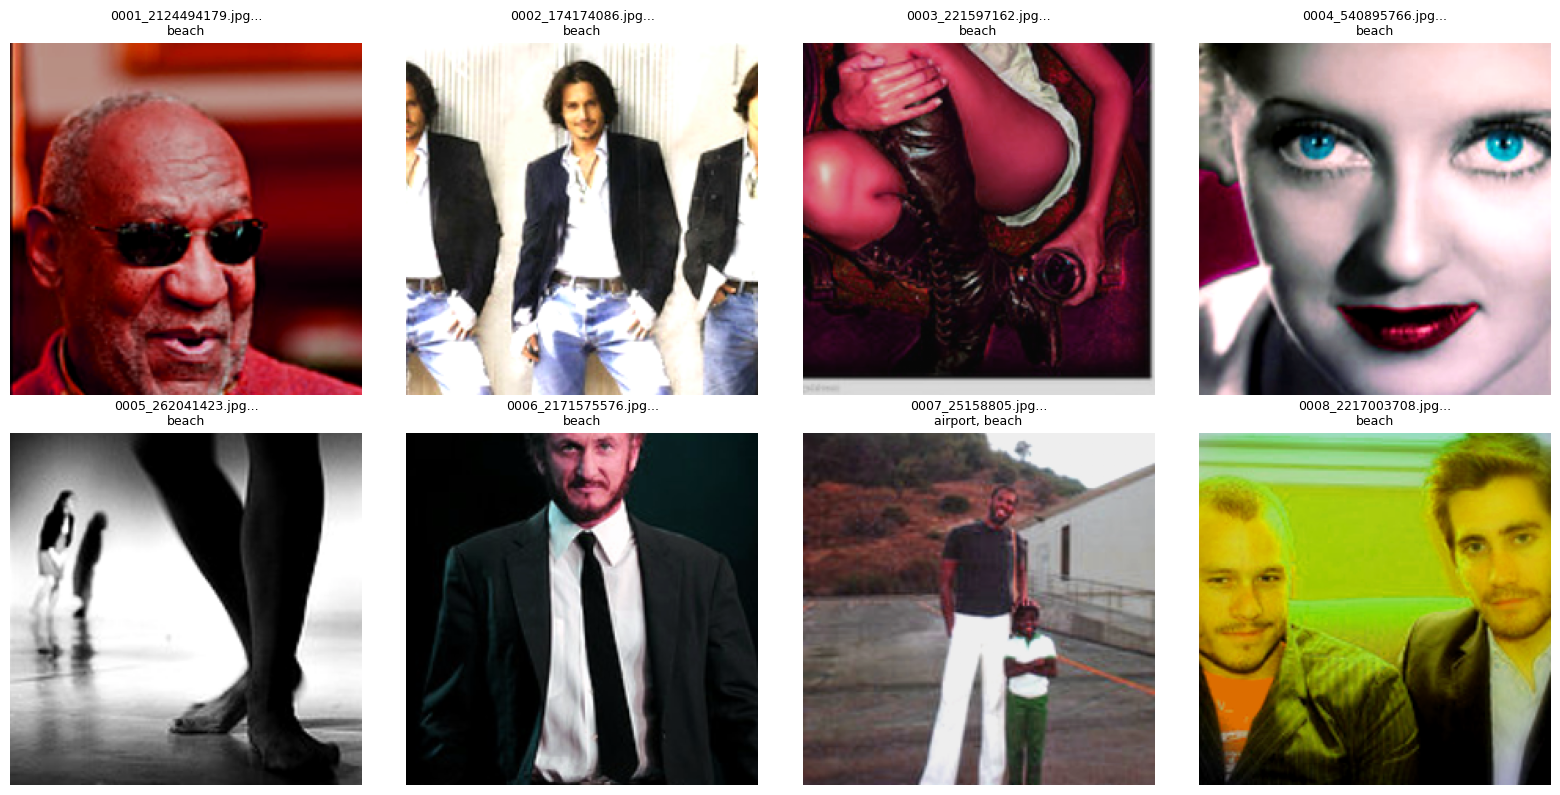

Sample visualization complete!


In [10]:
"""Visualize 8 sample images with their multi-labels."""

def denormalize(tensor, mean=IMAGENET_MEAN, std=IMAGENET_STD):
    """Denormalize image tensor for visualization."""
    tensor = tensor.clone()
    for t, m, s in zip(tensor, mean, std):
        t.mul_(s).add_(m)
    return torch.clamp(tensor, 0, 1)

# Concept names for NUS-WIDE 21 labels
CONCEPT_NAMES = [
    'airport', 'animal', 'beach', 'bear', 'birds', 'boats', 'book',
    'bridge', 'buildings', 'cars', 'castle', 'cat', 'computer',
    'coral', 'cow', 'dancing', 'dog', 'elephant', 'fish', 'flags', 'flower'
]

# Get 8 samples
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()

for i in range(8):
    img, label, filename = train_dataset[i]

    # Denormalize and convert to numpy
    img_show = denormalize(img).permute(1, 2, 0).numpy()

    # Get active labels
    active_labels = [CONCEPT_NAMES[j] for j, val in enumerate(label) if val == 1]

    # Plot
    axes[i].imshow(img_show)
    axes[i].axis('off')
    axes[i].set_title(f"{filename[:20]}...\n{', '.join(active_labels[:3])}",
                      fontsize=9)

    # Print label vector
    if i == 0:
        print(f"Sample {i} label vector:")
        print(label.numpy())
        print(f"Active concepts: {active_labels}\n")

plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, 'sample_images.png'), dpi=150, bbox_inches='tight')
plt.show()

print("Sample visualization complete!")


## Model Architecture — AAM-DSH

**Pipeline:**
```
Input Image (224×224×3)
    ↓
ResNet-50 Backbone (pretrained on ImageNet)
    ↓
Multi-level Feature Extraction: layer2, layer3, layer4
    ↓
Adaptive Attention Module (AAM) on each level
    ↓
Global Average Pooling → vectors v2, v3, v4
    ↓
Learnable Weighted Fusion: fused = w2*v2 + w3*v3 + w4*v4
    ↓
Projection MLP: fused → latent (512-dim)
    ↓
    ├─→ Hash Head: latent → K-bit codes (tanh activation)
    └─→ Classifier Head: latent → 21 classes (auxiliary loss)
```

**Why Three Levels?**
- **layer2:** High spatial resolution (56×56), captures fine details
- **layer3:** Medium resolution (28×28), captures mid-level semantics
- **layer4:** Low resolution (14×14), captures high-level global semantics

Combining multiple scales captures both local and global visual patterns.

**Adaptive Attention Module (AAM):**
- **Channel attention:** Which feature channels are important (what to attend)
- **Spatial attention:** Which spatial locations are important (where to attend)
- **Sequential application:** Channel → Spatial → refined feature map
- **Purpose:** Focus on salient regions (e.g., objects) and suppress background

This improves discriminative power for hashing by emphasizing semantically meaningful regions.

In [11]:
class ChannelAttention(nn.Module):
    """Channel attention based on Squeeze-and-Excitation."""

    def __init__(self, in_channels: int, reduction: int = 16):
        """
        Args:
            in_channels: Number of input channels
            reduction: Reduction ratio for bottleneck
        """
        super().__init__()
        self.avg_pool = nn.AdaptiveAvgPool2d(1)  # Global average pooling
        self.fc = nn.Sequential(
            nn.Linear(in_channels, in_channels // reduction, bias=False),
            nn.ReLU(inplace=True),
            nn.Linear(in_channels // reduction, in_channels, bias=False),
            nn.Sigmoid()
        )

    def forward(self, x):
        """
        Args:
            x: Input tensor (B, C, H, W)
        Returns:
            Attention-weighted features (B, C, H, W)
        """
        b, c, _, _ = x.size()
        # Squeeze: global spatial information
        y = self.avg_pool(x).view(b, c)
        # Excitation: compute channel weights
        y = self.fc(y).view(b, c, 1, 1)
        # Scale features by attention weights
        return x * y.expand_as(x)

print("Channel attention module defined!")


Channel attention module defined!


In [12]:
class SpatialAttention(nn.Module):
    """Spatial attention using channel-pooling and convolution."""

    def __init__(self, kernel_size: int = 7):
        """
        Args:
            kernel_size: Convolution kernel size for spatial attention
        """
        super().__init__()
        self.conv = nn.Conv2d(2, 1, kernel_size=kernel_size,
                              padding=kernel_size // 2, bias=False)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        """
        Args:
            x: Input tensor (B, C, H, W)
        Returns:
            Attention-weighted features (B, C, H, W)
        """
        # Channel pooling: max and average across channels
        avg_out = torch.mean(x, dim=1, keepdim=True)  # (B, 1, H, W)
        max_out, _ = torch.max(x, dim=1, keepdim=True)  # (B, 1, H, W)

        # Concatenate and convolve
        pool_out = torch.cat([avg_out, max_out], dim=1)  # (B, 2, H, W)
        attention = self.sigmoid(self.conv(pool_out))  # (B, 1, H, W)

        # Scale features by attention map
        return x * attention

print("Spatial attention module defined!")

Spatial attention module defined!


In [13]:
class AdaptiveAttentionModule(nn.Module):
    """Combined channel and spatial attention (AAM)."""

    def __init__(self, in_channels: int):
        """
        Args:
            in_channels: Number of input channels
        """
        super().__init__()
        self.channel_attention = ChannelAttention(in_channels)
        self.spatial_attention = SpatialAttention()

    def forward(self, x):
        """
        Apply channel attention then spatial attention.

        Args:
            x: Input features (B, C, H, W)
        Returns:
            Attention-refined features (B, C, H, W)
        """
        x = self.channel_attention(x)  # Channel attention first
        x = self.spatial_attention(x)   # Then spatial attention
        return x

print("Adaptive Attention Module (AAM) defined!")

Adaptive Attention Module (AAM) defined!


In [14]:
class AAMDSH(nn.Module):
    """AAM-DSH: Adaptive Attention Module - Deep Supervised Hashing."""

    def __init__(self, hash_length: int, num_classes: int, latent_dim: int = 512):
        """
        Args:
            hash_length: Length of binary hash codes
            num_classes: Number of semantic classes (21 for NUS-WIDE)
            latent_dim: Dimension of fused feature vector
        """
        super().__init__()
        self.hash_length = hash_length

        # ResNet-50 backbone (pretrained on ImageNet)
        resnet = models.resnet50(pretrained=True)

        # Extract backbone layers (up to layer4)
        self.conv1 = resnet.conv1
        self.bn1 = resnet.bn1
        self.relu = resnet.relu
        self.maxpool = resnet.maxpool
        self.layer1 = resnet.layer1
        self.layer2 = resnet.layer2  # Output: 512 channels
        self.layer3 = resnet.layer3  # Output: 1024 channels
        self.layer4 = resnet.layer4  # Output: 2048 channels

        # Adaptive attention modules for each level
        self.aam2 = AdaptiveAttentionModule(512)
        self.aam3 = AdaptiveAttentionModule(1024)
        self.aam4 = AdaptiveAttentionModule(2048)

        # Global pooling
        self.global_pool = nn.AdaptiveAvgPool2d(1)

        # Learnable fusion weights (initialized to 1.0)
        self.weight2 = nn.Parameter(torch.ones(1))
        self.weight3 = nn.Parameter(torch.ones(1))
        self.weight4 = nn.Parameter(torch.ones(1))

        # Projection MLP: fused features -> latent representation
        fusion_dim = 512 + 1024 + 2048  # Concatenated dimension
        self.projection = nn.Sequential(
            nn.Linear(fusion_dim, latent_dim),
            nn.BatchNorm1d(latent_dim),
            nn.ReLU(inplace=True),
            nn.Linear(latent_dim, latent_dim),
            nn.BatchNorm1d(latent_dim),
            nn.ReLU(inplace=True)
        )

        # Hash head: latent -> hash codes
        self.hash_head = nn.Linear(latent_dim, hash_length)

        # Auxiliary classifier head: latent -> class predictions
        self.classifier = nn.Linear(latent_dim, num_classes)

    def forward(self, x, return_latent=False):
        """
        Forward pass.

        Args:
            x: Input images (B, 3, 224, 224)
            return_latent: If True, also return latent features

        Returns:
            hash_logits: Continuous hash values (B, K)
            class_logits: Class predictions (B, num_classes)
            latent (optional): Latent features (B, latent_dim)
        """
        # Backbone forward pass
        x = self.conv1(x)
        x = self.bn1(x)
        x = self.relu(x)
        x = self.maxpool(x)
        x = self.layer1(x)

        # Multi-level feature extraction
        f2 = self.layer2(x)  # (B, 512, H/8, W/8)
        f3 = self.layer3(f2)  # (B, 1024, H/16, W/16)
        f4 = self.layer4(f3)  # (B, 2048, H/32, W/32)

        # Apply AAM to each level
        f2_att = self.aam2(f2)
        f3_att = self.aam3(f3)
        f4_att = self.aam4(f4)

        # Global average pooling on each level
        v2 = self.global_pool(f2_att).flatten(1)  # (B, 512)
        v3 = self.global_pool(f3_att).flatten(1)  # (B, 1024)
        v4 = self.global_pool(f4_att).flatten(1)  # (B, 2048)

        # Learnable weighted fusion (concatenate for this implementation)
        # Alternative: fused = self.weight2 * v2 + self.weight3 * v3 + self.weight4 * v4
        # We concatenate then project to allow learning complex fusion
        fused = torch.cat([v2, v3, v4], dim=1)  # (B, 3584)

        # Project to latent space
        latent = self.projection(fused)  # (B, latent_dim)

        # Hash head (continuous values in training)
        hash_logits = self.hash_head(latent)  # (B, hash_length)

        # Classifier head
        class_logits = self.classifier(latent)  # (B, num_classes)

        if return_latent:
            return hash_logits, class_logits, latent
        return hash_logits, class_logits

    def get_binary_codes(self, x):
        """
        Generate binary hash codes for retrieval.

        Args:
            x: Input images (B, 3, 224, 224)

        Returns:
            Binary codes in {-1, +1} (B, hash_length)
        """
        hash_logits, _ = self.forward(x)
        # Apply tanh then sign to get {-1, +1}
        return torch.sign(torch.tanh(hash_logits))

print("AAM-DSH model defined!")

AAM-DSH model defined!


In [15]:
"""Instantiate model and print architecture summary."""

model = AAMDSH(hash_length=HASH_LENGTH, num_classes=NUM_CLASSES, latent_dim=LATENT_DIM)
model = model.to(device)

# Count parameters
def count_parameters(model):
    """Count trainable and total parameters."""
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    total = sum(p.numel() for p in model.parameters())
    return trainable, total

trainable_params, total_params = count_parameters(model)
print(f"Model Parameters:")
print(f"  Trainable: {trainable_params:,}")
print(f"  Total: {total_params:,}")
print(f"  Size: ~{total_params * 4 / 1e6:.2f} MB (float32)")

# Test forward pass with dummy input
dummy_input = torch.randn(2, 3, 224, 224).to(device)
with torch.no_grad():
    hash_out, class_out = model(dummy_input)
    print(f"\nForward pass test:")
    print(f"  Input shape: {dummy_input.shape}")
    print(f"  Hash output shape: {hash_out.shape}")
    print(f"  Class output shape: {class_out.shape}")

print("\n✓ Model instantiation successful!")


/usr/local/lib/python3.11/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet50_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet50_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth
100%|██████████| 97.8M/97.8M [00:00<00:00, 185MB/s]


Model Parameters:
  Trainable: 26,340,286
  Total: 26,340,286
  Size: ~105.36 MB (float32)

Forward pass test:
  Input shape: torch.Size([2, 3, 224, 224])
  Hash output shape: torch.Size([2, 64])
  Class output shape: torch.Size([2, 21])

✓ Model instantiation successful!


## Loss Functions

**1. Semantic Loss (L_sem):**
Multi-label binary cross entropy between classifier predictions and ground truth labels.

Formula: `L_sem = BCEWithLogitsLoss(class_logits, labels)`

Purpose: Ensures hash codes preserve semantic information.

**2. Quantization Loss (L_q):**
Encourages continuous hash values to be close to {-1, +1}.

Formula: `L_q = mean((|h_real| - 1)²)`

where `h_real = tanh(hash_logits)`

Purpose: Minimize quantization error when converting to binary codes.

**3. Balance Loss (L_b):**
Encourages each hash bit to have balanced distribution (mean ≈ 0).

Formula: `L_b = Σ_k (mean(h_real[:, k]))²`

Purpose: Maximize information content; prevent bits from being constant.

**Total Loss:**
```
L_total = L_sem + λ_q * L_q + λ_b * L_b
```

Default weights: `λ_q = 0.1`, `λ_b = 0.01`

**Straight-Through Estimator (STE):**
During training, we use `tanh(hash_logits)` for continuous values.
At inference, we use `sign(tanh(hash_logits))` for binary codes.
The gradient flows through tanh during backpropagation.

In [16]:
class HashingLoss(nn.Module):
    """Combined loss for deep supervised hashing."""

    def __init__(self, lambda_q: float = 0.1, lambda_b: float = 0.01):
        """
        Args:
            lambda_q: Weight for quantization loss
            lambda_b: Weight for balance loss
        """
        super().__init__()
        self.lambda_q = lambda_q
        self.lambda_b = lambda_b
        self.bce_loss = nn.BCEWithLogitsLoss()

    def forward(self, hash_logits, class_logits, labels):
        """
        Compute total hashing loss.

        Args:
            hash_logits: Raw hash outputs (B, K)
            class_logits: Classifier outputs (B, num_classes)
            labels: Ground truth labels (B, num_classes)

        Returns:
            total_loss, loss_dict with individual losses
        """
        # 1. Semantic loss (classification)
        loss_sem = self.bce_loss(class_logits, labels)

        # Apply tanh to get continuous hash values in (-1, 1)
        h_real = torch.tanh(hash_logits)

        # 2. Quantization loss: push values toward {-1, +1}
        loss_q = torch.mean((torch.abs(h_real) - 1) ** 2)

        # 3. Balance loss: encourage each bit to have mean ≈ 0
        bit_means = torch.mean(h_real, dim=0)  # Mean per bit across batch
        loss_b = torch.sum(bit_means ** 2)

        # Total loss
        total_loss = loss_sem + self.lambda_q * loss_q + self.lambda_b * loss_b

        # Return loss breakdown for logging
        loss_dict = {
            'total': total_loss.item(),
            'semantic': loss_sem.item(),
            'quantization': loss_q.item(),
            'balance': loss_b.item()
        }

        return total_loss, loss_dict

# Instantiate loss function
criterion = HashingLoss(lambda_q=LAMBDA_Q, lambda_b=LAMBDA_B)
print("Loss function defined!")
print(f"  λ_q (quantization): {LAMBDA_Q}")
print(f"  λ_b (balance): {LAMBDA_B}")

Loss function defined!
  λ_q (quantization): 0.1
  λ_b (balance): 0.01


In [17]:
backbone_params = []
head_params = []

for name, param in model.named_parameters():
    if 'conv1' in name or 'bn1' in name or 'layer' in name:
        backbone_params.append(param)
    else:
        head_params.append(param)

print(f"Parameter groups:")
print(f"  Backbone parameters: {sum(p.numel() for p in backbone_params):,}")
print(f"  Head parameters: {sum(p.numel() for p in head_params):,}")

# Create optimizer with parameter groups
optimizer = torch.optim.AdamW([
    {'params': backbone_params, 'lr': LEARNING_RATE_BACKBONE},
    {'params': head_params, 'lr': LEARNING_RATE_HEAD}
], weight_decay=WEIGHT_DECAY)

# Cosine annealing learning rate scheduler
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer, T_max=NUM_EPOCHS, eta_min=1e-6
)

print(f"\nOptimizer: AdamW")
print(f"  Backbone LR: {LEARNING_RATE_BACKBONE}")
print(f"  Head LR: {LEARNING_RATE_HEAD}")
print(f"  Weight decay: {WEIGHT_DECAY}")
print(f"\nScheduler: CosineAnnealingLR")
print(f"  T_max: {NUM_EPOCHS} epochs")

Parameter groups:
  Backbone parameters: 23,508,032
  Head parameters: 2,832,254

Optimizer: AdamW
  Backbone LR: 0.0001
  Head LR: 0.001
  Weight decay: 0.0001

Scheduler: CosineAnnealingLR
  T_max: 15 epochs


In [18]:
def train_epoch(model, train_loader, criterion, optimizer, device, epoch):
    """Train for one epoch."""
    model.train()

    total_loss = 0
    loss_sem_sum = 0
    loss_q_sum = 0
    loss_b_sum = 0
    num_batches = 0

    for batch_idx, (images, labels, _) in enumerate(train_loader):
        images = images.to(device)
        labels = labels.to(device)

        # Forward pass
        hash_logits, class_logits = model(images)

        # Compute loss
        loss, loss_dict = criterion(hash_logits, class_logits, labels)

        # Backward pass
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        # Accumulate losses
        total_loss += loss_dict['total']
        loss_sem_sum += loss_dict['semantic']
        loss_q_sum += loss_dict['quantization']
        loss_b_sum += loss_dict['balance']
        num_batches += 1

        # Print progress every 50 batches
        if (batch_idx + 1) % 50 == 0:
            avg_loss = total_loss / num_batches
            print(f"  Batch [{batch_idx+1}/{len(train_loader)}] - Loss: {avg_loss:.4f}")

    # Return average losses
    return {
        'total': total_loss / num_batches,
        'semantic': loss_sem_sum / num_batches,
        'quantization': loss_q_sum / num_batches,
        'balance': loss_b_sum / num_batches
    }

def save_checkpoint(model, optimizer, scheduler, epoch, save_path):
    """Save model checkpoint."""
    checkpoint = {
        'epoch': epoch,
        'model_state_dict': model.state_dict(),
        'optimizer_state_dict': optimizer.state_dict(),
        'scheduler_state_dict': scheduler.state_dict(),
        'hash_length': HASH_LENGTH
    }
    torch.save(checkpoint, save_path)
    print(f"  Checkpoint saved: {save_path}")

print("Training functions defined!")


Training functions defined!


In [19]:
def compute_codes_and_labels(model, data_loader, device):
    """
    Compute binary hash codes and labels for entire dataset.

    Returns:
        codes: Binary codes (N, K) in {-1, +1}
        labels: Ground truth labels (N, num_classes)
        filenames: Image filenames (N,)
    """
    model.eval()

    all_codes = []
    all_labels = []
    all_filenames = []

    with torch.no_grad():
        for images, labels, filenames in data_loader:
            images = images.to(device)

            # Get binary codes
            codes = model.get_binary_codes(images)  # (B, K) in {-1, +1}

            all_codes.append(codes.cpu())
            all_labels.append(labels)
            all_filenames.extend(filenames)

    # Concatenate all batches
    all_codes = torch.cat(all_codes, dim=0).numpy()  # (N, K)
    all_labels = torch.cat(all_labels, dim=0).numpy()  # (N, num_classes)

    return all_codes, all_labels, all_filenames

def hamming_distance_numpy(query_code, database_codes):
    """
    Compute Hamming distances between query and all database codes.

    Args:
        query_code: Single query code (K,) in {-1, +1}
        database_codes: Database codes (N, K) in {-1, +1}

    Returns:
        Hamming distances (N,)
    """
    # XOR operation: same bits = 0, different bits = 1
    # For {-1, +1} codes: (a != b) is equivalent to (a * b == -1)
    xor = (query_code != database_codes).astype(np.float32)
    hamming_dist = np.sum(xor, axis=1)
    return hamming_dist

def compute_average_precision(relevant, rankings):
    """
    Compute Average Precision for a single query.

    Args:
        relevant: Boolean array indicating relevant items (N,)
        rankings: Ranked indices (N,)

    Returns:
        Average Precision score
    """
    relevant_ranked = relevant[rankings]

    # Positions where relevant items appear (1-indexed)
    relevant_positions = np.where(relevant_ranked)[0] + 1

    if len(relevant_positions) == 0:
        return 0.0

    # Precision at each relevant position
    precisions = np.arange(1, len(relevant_positions) + 1) / relevant_positions

    # Average precision
    ap = np.mean(precisions)
    return ap

def compute_map(query_codes, query_labels, database_codes, database_labels):
    """
    Compute Mean Average Precision (mAP).

    Two images are relevant if they share at least one label.

    Args:
        query_codes: Query binary codes (N_q, K)
        query_labels: Query labels (N_q, num_classes)
        database_codes: Database codes (N_db, K)
        database_labels: Database labels (N_db, num_classes)

    Returns:
        mAP score
    """
    num_queries = len(query_codes)
    aps = []

    for i in range(num_queries):
        # Compute Hamming distances
        hamming_dists = hamming_distance_numpy(query_codes[i], database_codes)

        # Rank database by ascending Hamming distance
        rankings = np.argsort(hamming_dists)

        # Determine relevant items (share at least one label)
        query_label = query_labels[i]
        # Dot product > 0 means at least one common label
        relevant = (database_labels @ query_label) > 0

        # Compute AP for this query
        ap = compute_average_precision(relevant, rankings)
        aps.append(ap)

        if (i + 1) % 100 == 0:
            print(f"  Processed {i+1}/{num_queries} queries")

    # Mean Average Precision
    map_score = np.mean(aps)
    return map_score, aps

def compute_precision_at_k(query_codes, query_labels, database_codes,
                           database_labels, k_values=[1, 5, 10, 20]):
    """
    Compute Precision@K for multiple K values.

    Returns:
        Dictionary {K: precision_score}
    """
    num_queries = len(query_codes)
    precision_scores = {k: [] for k in k_values}

    for i in range(num_queries):
        hamming_dists = hamming_distance_numpy(query_codes[i], database_codes)
        rankings = np.argsort(hamming_dists)

        query_label = query_labels[i]
        relevant = (database_labels @ query_label) > 0

        for k in k_values:
            top_k = rankings[:k]
            precision = np.sum(relevant[top_k]) / k
            precision_scores[k].append(precision)

    # Average across all queries
    avg_precisions = {k: np.mean(precision_scores[k]) for k in k_values}
    return avg_precisions

print("Evaluation utilities defined!")


Evaluation utilities defined!


In [20]:
def build_faiss_index(database_codes):
    """
    Build FAISS binary index from database codes.

    Args:
        database_codes: Binary codes (N, K) in {-1, +1}

    Returns:
        FAISS binary index
    """
    if not FAISS_AVAILABLE:
        print("FAISS not available, skipping index build")
        return None

    # Convert {-1, +1} to {0, 1} for FAISS
    binary_codes = ((database_codes + 1) / 2).astype(np.uint8)  # (N, K)

    # Pack bits into bytes
    K = database_codes.shape[1]
    assert K % 8 == 0, "Hash length must be multiple of 8 for FAISS"

    packed_codes = np.packbits(binary_codes, axis=1)  # (N, K/8)

    # Build binary flat index
    index = faiss.IndexBinaryFlat(K)
    index.add(packed_codes)

    print(f"FAISS index built: {index.ntotal} codes")
    return index

def search_faiss(query_code, index, k=100):
    """
    Search FAISS index for top-k nearest neighbors.

    Args:
        query_code: Query binary code (K,) in {-1, +1}
        index: FAISS binary index
        k: Number of neighbors to retrieve

    Returns:
        distances: Hamming distances (k,)
        indices: Database indices (k,)
    """
    # Convert to binary and pack
    binary_query = ((query_code + 1) / 2).astype(np.uint8)
    packed_query = np.packbits(binary_query).reshape(1, -1)

    # Search
    distances, indices = index.search(packed_query, k)

    return distances[0], indices[0]

print("FAISS utilities defined!")

FAISS utilities defined!


In [21]:
history = {
    'epoch': [],
    'loss_total': [],
    'loss_semantic': [],
    'loss_quantization': [],
    'loss_balance': [],
    'learning_rate': []
}

print("=" * 60)
print("STARTING TRAINING")
print("=" * 60)
print(f"Epochs: {NUM_EPOCHS}")
print(f"Batch size: {BATCH_SIZE}")
print(f"Device: {device}")
print("=" * 60)

for epoch in range(1, NUM_EPOCHS + 1):
    print(f"\nEpoch [{epoch}/{NUM_EPOCHS}]")
    print("-" * 60)

    # Train for one epoch
    train_losses = train_epoch(model, train_loader, criterion, optimizer, device, epoch)

    # Update learning rate
    current_lr = optimizer.param_groups[0]['lr']
    scheduler.step()

    # Log losses
    history['epoch'].append(epoch)
    history['loss_total'].append(train_losses['total'])
    history['loss_semantic'].append(train_losses['semantic'])
    history['loss_quantization'].append(train_losses['quantization'])
    history['loss_balance'].append(train_losses['balance'])
    history['learning_rate'].append(current_lr)

    print(f"\n  Epoch {epoch} Summary:")
    print(f"    Total Loss: {train_losses['total']:.4f}")
    print(f"    Semantic: {train_losses['semantic']:.4f}")
    print(f"    Quantization: {train_losses['quantization']:.4f}")
    print(f"    Balance: {train_losses['balance']:.4f}")
    print(f"    LR: {current_lr:.6f}")

    # Save checkpoint
    if epoch % SAVE_CHECKPOINT_EVERY == 0:
        checkpoint_path = os.path.join(
            CHECKPOINT_DIR, f"aamdsh_epoch{epoch}_h{HASH_LENGTH}.pth"
        )
        save_checkpoint(model, optimizer, scheduler, epoch, checkpoint_path)

    print("-" * 60)

# Save final model
final_model_path = os.path.join(CHECKPOINT_DIR, f"aamdsh_final_h{HASH_LENGTH}.pth")
save_checkpoint(model, optimizer, scheduler, NUM_EPOCHS, final_model_path)

print("\n" + "=" * 60)
print("TRAINING COMPLETE!")
print("=" * 60)

STARTING TRAINING
Epochs: 15
Batch size: 128
Device: cuda

Epoch [1/15]
------------------------------------------------------------
  Batch [50/1514] - Loss: 0.2380
  Batch [100/1514] - Loss: 0.1940
  Batch [150/1514] - Loss: 0.1769
  Batch [200/1514] - Loss: 0.1684
  Batch [250/1514] - Loss: 0.1619
  Batch [300/1514] - Loss: 0.1577
  Batch [350/1514] - Loss: 0.1540
  Batch [400/1514] - Loss: 0.1514
  Batch [450/1514] - Loss: 0.1492
  Batch [500/1514] - Loss: 0.1475
  Batch [550/1514] - Loss: 0.1461
  Batch [600/1514] - Loss: 0.1446
  Batch [650/1514] - Loss: 0.1436
  Batch [700/1514] - Loss: 0.1426
  Batch [750/1514] - Loss: 0.1417
  Batch [800/1514] - Loss: 0.1409
  Batch [850/1514] - Loss: 0.1403
  Batch [900/1514] - Loss: 0.1396
  Batch [950/1514] - Loss: 0.1391
  Batch [1000/1514] - Loss: 0.1384
  Batch [1050/1514] - Loss: 0.1379
  Batch [1100/1514] - Loss: 0.1374
  Batch [1150/1514] - Loss: 0.1369
  Batch [1200/1514] - Loss: 0.1364
  Batch [1250/1514] - Loss: 0.1361
  Batch [130

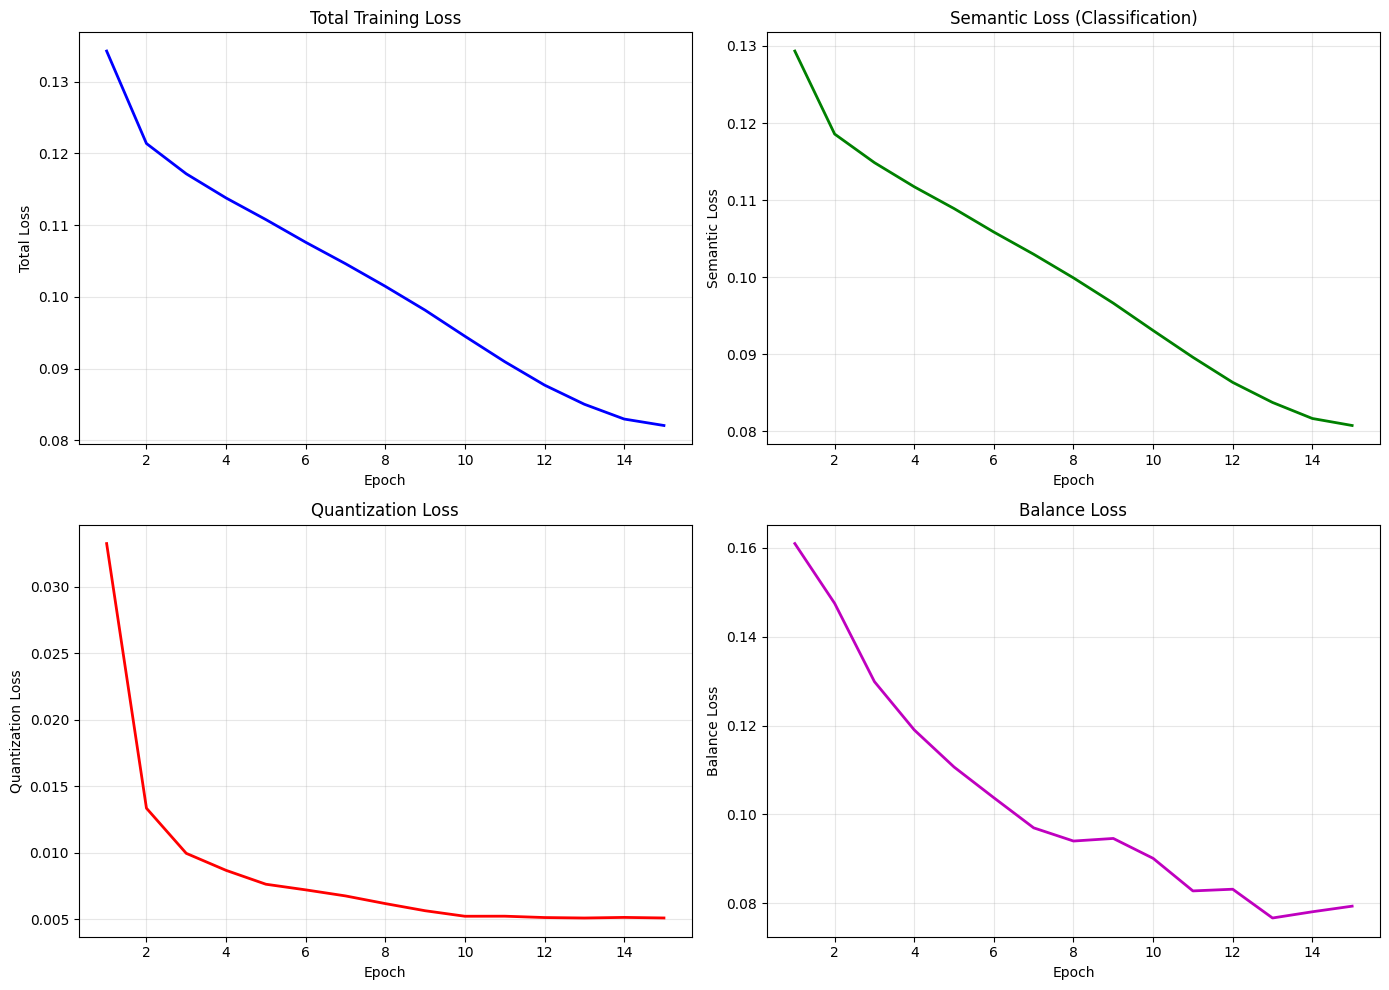

Training curves saved!
GENERATING BINARY CODES FOR DATABASE
Computing database codes...
✓ Database codes: (193734, 64)

Computing test/query codes...
✓ Test codes: (2100, 64)

✓ Binary codes saved to /kaggle/working/
  Database codes: (193734, 8) (packed)
  Test codes: (2100, 8) (packed)

Building FAISS binary index...
FAISS index built: 193734 codes
✓ FAISS index ready for fast search


In [22]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Total loss
axes[0, 0].plot(history['epoch'], history['loss_total'], 'b-', linewidth=2)
axes[0, 0].set_xlabel('Epoch')
axes[0, 0].set_ylabel('Total Loss')
axes[0, 0].set_title('Total Training Loss')
axes[0, 0].grid(True, alpha=0.3)

# Semantic loss
axes[0, 1].plot(history['epoch'], history['loss_semantic'], 'g-', linewidth=2)
axes[0, 1].set_xlabel('Epoch')
axes[0, 1].set_ylabel('Semantic Loss')
axes[0, 1].set_title('Semantic Loss (Classification)')
axes[0, 1].grid(True, alpha=0.3)

# Quantization loss
axes[1, 0].plot(history['epoch'], history['loss_quantization'], 'r-', linewidth=2)
axes[1, 0].set_xlabel('Epoch')
axes[1, 0].set_ylabel('Quantization Loss')
axes[1, 0].set_title('Quantization Loss')
axes[1, 0].grid(True, alpha=0.3)

# Balance loss
axes[1, 1].plot(history['epoch'], history['loss_balance'], 'm-', linewidth=2)
axes[1, 1].set_xlabel('Epoch')
axes[1, 1].set_ylabel('Balance Loss')
axes[1, 1].set_title('Balance Loss')
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, 'training_curves.png'), dpi=150, bbox_inches='tight')
plt.show()

print("Training curves saved!")

### CELL 29: Generate Database Binary Codes (Code)
"""Compute and save binary codes for entire database."""

print("=" * 60)
print("GENERATING BINARY CODES FOR DATABASE")
print("=" * 60)

# Compute codes for database
print("Computing database codes...")
database_codes, database_labels, database_filenames = compute_codes_and_labels(
    model, database_loader, device
)
print(f"✓ Database codes: {database_codes.shape}")

# Compute codes for test set (queries)
print("\nComputing test/query codes...")
test_codes, test_labels, test_filenames = compute_codes_and_labels(
    model, test_loader, device
)
print(f"✓ Test codes: {test_codes.shape}")

# Convert {-1, +1} to {0, 1} for storage
database_codes_binary = ((database_codes + 1) / 2).astype(np.uint8)
test_codes_binary = ((test_codes + 1) / 2).astype(np.uint8)

# Pack bits for efficient storage
database_codes_packed = np.packbits(database_codes_binary, axis=1)
test_codes_packed = np.packbits(test_codes_binary, axis=1)

# Save to disk
np.save(os.path.join(OUTPUT_ROOT, 'database_codes.npy'), database_codes_packed)
np.save(os.path.join(OUTPUT_ROOT, 'test_codes.npy'), test_codes_packed)
np.save(os.path.join(OUTPUT_ROOT, 'database_labels.npy'), database_labels)
np.save(os.path.join(OUTPUT_ROOT, 'test_labels.npy'), test_labels)

# Save filenames
with open(os.path.join(OUTPUT_ROOT, 'database_filenames.txt'), 'w') as f:
    f.write('\n'.join(database_filenames))
with open(os.path.join(OUTPUT_ROOT, 'test_filenames.txt'), 'w') as f:
    f.write('\n'.join(test_filenames))

print(f"\n✓ Binary codes saved to {OUTPUT_ROOT}")
print(f"  Database codes: {database_codes_packed.shape} (packed)")
print(f"  Test codes: {test_codes_packed.shape} (packed)")

### CELL 30: Build FAISS Index (Optional) (Code)
"""Build FAISS binary index for fast retrieval (if available)."""

if FAISS_AVAILABLE and HASH_LENGTH % 8 == 0:
    print("\nBuilding FAISS binary index...")
    faiss_index = build_faiss_index(database_codes)
    print("✓ FAISS index ready for fast search")
else:
    faiss_index = None
    if HASH_LENGTH % 8 != 0:
        print(f"\nSkipping FAISS (hash length {HASH_LENGTH} not multiple of 8)")
    else:
        print("\nFAISS not available, will use NumPy for search")


In [23]:
print("\n" + "=" * 60)
print("EVALUATING: MEAN AVERAGE PRECISION (mAP)")
print("=" * 60)

map_score, aps = compute_map(
    test_codes, test_labels,
    database_codes, database_labels
)

print(f"\n✓ mAP @ {HASH_LENGTH} bits: {map_score:.4f}")
print(f"  Min AP: {np.min(aps):.4f}")
print(f"  Max AP: {np.max(aps):.4f}")
print(f"  Median AP: {np.median(aps):.4f}")




EVALUATING: MEAN AVERAGE PRECISION (mAP)
  Processed 100/2100 queries
  Processed 200/2100 queries
  Processed 300/2100 queries
  Processed 400/2100 queries
  Processed 500/2100 queries
  Processed 600/2100 queries
  Processed 700/2100 queries
  Processed 800/2100 queries
  Processed 900/2100 queries
  Processed 1000/2100 queries
  Processed 1100/2100 queries
  Processed 1200/2100 queries
  Processed 1300/2100 queries
  Processed 1400/2100 queries
  Processed 1500/2100 queries
  Processed 1600/2100 queries
  Processed 1700/2100 queries
  Processed 1800/2100 queries
  Processed 1900/2100 queries
  Processed 2000/2100 queries
  Processed 2100/2100 queries

✓ mAP @ 64 bits: 0.6638
  Min AP: 0.0149
  Max AP: 0.9162
  Median AP: 0.7842


In [24]:
print("\n" + "=" * 60)
print("EVALUATING: PRECISION@K")
print("=" * 60)

k_values = [1, 5, 10, 20, 50, 100]
precision_at_k = compute_precision_at_k(
    test_codes, test_labels,
    database_codes, database_labels,
    k_values=k_values
)

print("\nPrecision@K:")
for k, prec in precision_at_k.items():
    print(f"  P@{k:3d}: {prec:.4f}")


EVALUATING: PRECISION@K

Precision@K:
  P@  1: 0.7224
  P@  5: 0.8102
  P@ 10: 0.8195
  P@ 20: 0.8116
  P@ 50: 0.8056
  P@100: 0.8007


In [25]:
results_summary = {
    'Hash Length': HASH_LENGTH,
    'mAP': map_score,
    **{f'P@{k}': precision_at_k[k] for k in [1, 5, 10, 20]}
}

# Save results to JSON
results_json_path = os.path.join(RESULTS_DIR, f'results_h{HASH_LENGTH}.json')
with open(results_json_path, 'w') as f:
    json.dump(results_summary, f, indent=2)

print("\n" + "=" * 60)
print("RESULTS SUMMARY")
print("=" * 60)
print(f"\nHash Length: {HASH_LENGTH} bits")
print(f"mAP: {map_score:.4f}")
print("\nPrecision@K:")
for k in [1, 5, 10, 20]:
    print(f"  P@{k}: {precision_at_k[k]:.4f}")
print(f"\nResults saved to: {results_json_path}")


RESULTS SUMMARY

Hash Length: 64 bits
mAP: 0.6638

Precision@K:
  P@1: 0.7224
  P@5: 0.8102
  P@10: 0.8195
  P@20: 0.8116

Results saved to: /kaggle/working/results/results_h64.json
